# Churn Radar: Phase 2 Notebook
**Sadan Khan · KSBL DATA722 Generative AI & Strategic Forecasting**

Live application: **https://churn-radar-rosy.vercel.app** · Code: **https://github.com/Sadankhan7731/churn-radar**

This notebook is the working record of Phase 2. It builds **Use Case A** from my Phase 1 assessment (churn prediction with a plain-English weekly summary for the retention team, verdict *Go, build as scoped*) and tests it against the targets I fixed in Phase 1, before building.

| Section | What it covers | Brief requirement |
|---|---|---|
| 1 | Synthetic data | Phase 1 rule: no real customer data |
| 2 | Churn model and its evaluation | Evaluation against Phase 1 targets |
| 3 | The LLM core: facts packet, prompts, judge, repair loop | Prompts, context design, agent loop |
| 4 | Evaluating the AI memorandum | Evaluation with scores |
| 5 | Development log: what failed and what I changed | At least one failure |
| 6 | Tokens and cost | Cost of a representative run |
| 7 | Honesty section | What it gets wrong, what I would not ship, what it costs |

> All subscriber data in this notebook is **synthetic**. No real customer record is used anywhere.

In [1]:
import json, sys, time, warnings, runpy, io, contextlib
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sys.path.insert(0, "api")
import _note_engine as engine
print("Writer model:", engine.MODEL, "| Judge model:", engine.JUDGE_MODEL,
      "| API key configured:", bool(engine.load_key()))

Writer model: openai/gpt-oss-120b | Judge model: qwen/qwen3.8-27b | API key configured: True


## 1. Synthetic data

**Why synthetic?** In Phase 1 (row 6b) I wrote that raw subscriber data must stay inside the company. A public demo must therefore run on fake data, but data that *behaves* like the real thing.

**How:** I generate 20,000 subscribers with the same kinds of columns we hold at work (plan, payment channel, watch time, failed renewals, support tickets, buffering). Then I decide the **true rules** of who cancels, for example watching less, failed renewals and short tenure, and add random noise because real behaviour is messy.

Because I know the true rules, I can later check whether the model **rediscovers** them. With real data that check is impossible.

In [2]:
with contextlib.redirect_stdout(io.StringIO()) as out:
    runpy.run_path("src/step1_generate_data.py", run_name="__main__")
print(out.getvalue().split("First 3 rows")[0])
df = pd.read_csv("data/subscribers.csv")
df.head()

Saved 20,000 subscribers to data/subscribers.csv
Churn rate: 9.2%   (Phase 1 assumption: ~9%)
Average revenue per subscriber: PKR 292   (Phase 1: ~250-300)

Churn rate by plan:
plan
Daily             11.4%
Monthly            7.9%
Sports Premium     9.6%
Weekly             7.8%

Churn rate by number of failed renewals:
failed_renewals_30d
0     6.6%
1    11.3%
2    15.3%
3    28.6%




,subscriber_id,payment_channel,plan,monthly_revenue_pkr,city,device,favourite_genre,tenure_days,watch_min_prev_7d,watch_min_last_7d,sessions_7d,days_since_active,failed_renewals_30d,support_tickets_30d,buffering_errors_7d,used_discount,sports_season_over,churned_next_30d
0,SUB000001,Operator 4,Monthly,250,Lahore,Smart TV,Movies,415,229.0,193.0,7,11,1,1,5,0,0,0
1,SUB000002,Operator 2,Sports Premium,450,Karachi,iOS,Sports,300,493.0,570.0,19,1,0,0,0,0,0,0
2,SUB000003,Wallet,Daily,300,Karachi,Smart TV,Movies,838,249.0,194.0,5,2,0,0,7,0,0,0
3,SUB000004,Operator 3,Daily,300,Karachi,Web,Movies,202,261.0,243.0,5,2,1,1,2,1,0,0
4,SUB000005,Operator 1,Monthly,250,Other,Android,Drama,305,685.0,704.0,14,1,0,0,3,0,0,0


**Reading the output.** The synthetic base matches the Phase 1 assumptions: about 9% monthly churn and average revenue near PKR 290. The churn rate rises steeply with failed renewals, as it does in carrier billing, where a low prepaid balance makes renewals fail.

## 2. The churn model and its evaluation

**Method.** I hide 30% of subscribers (6,000) as a test set the model never sees, train on the other 70%, then compare predictions with what really happened.

I train **two** models:
* **Logistic regression:** simple, explainable, the baseline.
* **Gradient boosting:** more powerful, can find non-linear patterns.

**Decision rule, set before seeing results:** use gradient boosting only if it improves AUC by at least 0.01. Otherwise keep the simpler model, because the retention team needs to understand *why* someone is flagged.

**Phase 1 targets (rows 7 and 7a):** AUC ≥ 0.75; precision in the top 10% ≥ 40%; and in the high-risk band, predicted churn within 5 points of actual churn (the "confidently wrong" check).

In [3]:
with contextlib.redirect_stdout(io.StringIO()) as out:
    runpy.run_path("src/step2_train_and_evaluate.py", run_name="__main__")
print(out.getvalue())

Test set: 6,000 subscribers never seen in training, real churn rate 9.2%

Metric                                      Logistic regression (baseline)               Gradient boosting
AUC (target >= 0.75)                                                 0.743                           0.734
Precision in top 10% (target >= 40%)                                 0.277                           0.285
Recall in top 10%                                                    0.301                            0.31
Lift in top 10% (x better than random)                                3.01                             3.1
Brier score (lower = better)                                        0.0766                          0.0771
Top band: predicted churn                                            0.312                           0.274
Top band: actual churn                                               0.277                           0.285

Chosen model: Logistic regression (baseline)  (rule: use gradient boo

In [4]:
m = json.load(open("outputs/model_metrics.json"))
rows = {name: {k: r[k] for k in ["auc", "precision_top10", "recall_top10", "lift_top10", "brier"]}
        for name, r in m["results"].items()}
rows["Perfect model (knows the true rules)"] = m["ceiling"]
table = pd.DataFrame(rows).T
table.columns = ["AUC", "Precision top 10%", "Recall top 10%", "Lift top 10%", "Brier score"]
table.style.format({"AUC": "{:.3f}", "Precision top 10%": "{:.1%}", "Recall top 10%": "{:.1%}",
                    "Lift top 10%": "{:.2f}x", "Brier score": "{:.4f}"})

,AUC,Precision top 10%,Recall top 10%,Lift top 10%,Brier score
Logistic regression (baseline),0.743,27.7%,30.1%,3.01x,0.0766
Gradient boosting,0.734,28.5%,31.0%,3.10x,0.0771
Perfect model (knows the true rules),0.783,34.8%,37.9%,3.79x,0.0727


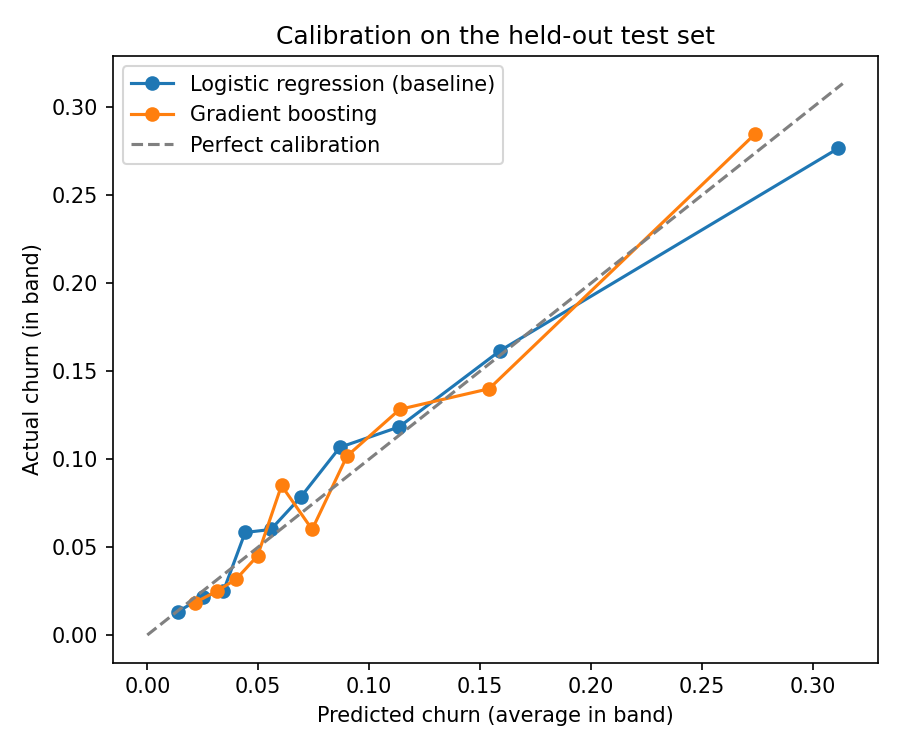

In [5]:
display(Image("outputs/calibration.png", width=480))

**What the results mean.**
* Gradient boosting was **not** better (AUC 0.734 vs 0.743), so the simpler logistic regression is used.
* **Two of three Phase 1 targets were missed:** AUC 0.743 (target 0.75) and top-10% precision 27.7% (target 40%).
* **Calibration passed.** In the highest-risk band the model predicts about 31% churn and 28% actually churn, and every point sits close to the diagonal. The model is **not confidently wrong**, which was my main safety concern in Phase 1.
* **The ceiling check.** A *perfect* model that knows the exact true rules reaches only AUC 0.783 and 34.8% precision. So **the 40% target was not reachable on this data by any model**, and ours reaches about **95% of the attainable AUC**. The target was too ambitious for a 9% base rate with noisy behaviour. I kept the honest result rather than making the synthetic data cleaner to pass the target.
* **Business value anyway:** contacting the top 10% reaches **3 times** more real leavers than contacting people at random.

### Did the model learn the real rules?

In [6]:
with contextlib.redirect_stdout(io.StringIO()) as out:
    runpy.run_path("src/step4_explain_and_segment.py", run_name="__main__")
d = json.load(open("public/data/dashboard.json"))
pd.DataFrame(d["rule_check"])

,feature,true_effect,model_coefficient,matches
0,watch_change_pct,lowers churn,-0.617,1.0
1,days_since_active,raises churn,0.348,1.0
2,failed_renewals_30d,raises churn,0.434,1.0
3,support_tickets_30d,raises churn,0.226,1.0
4,buffering_errors_7d,raises churn,0.130,1.0
5,tenure_days,lowers churn,-0.267,1.0
6,sports_season_over,raises churn,0.284,1.0
7,used_discount,raises churn,0.091,1.0


All eight true rules were recovered with the correct direction. The model was never told them. This is the strongest evidence that it learns real patterns rather than noise.

Step 4 also turns each score into **three plain-English reasons** (for example "Inactive for 23 days") by multiplying each coefficient by how far the subscriber is from average. A reason is only shown if it is actually true for that person. That rule is reused later by the hallucination check.

In [7]:
w = d["watchlist"][0]
print(f"Riskiest subscriber {w['id']}: {w['score']:.0%} chance of cancelling, {w['plan']} via {w['channel']}")
for r in w["reasons"]:
    print("  -", r["text"])

Riskiest subscriber SUB017160: 89% chance of cancelling, Sports Premium via Operator 3
  - Inactive for 23 days
  - 3 support ticket(s) in 30 days
  - Watch time down 41% vs last week


## 3. The LLM core: context design, prompts, judge and repair loop

This is the centre of the system. A single run does the following:

```
dashboard numbers ──► 13 numbered FACTS (aggregates only) ──► privacy check
        ──► WRITER (gpt-oss-120b) drafts memo, must cite a fact per sentence
        ──► NUMBER CHECK (code): citation exists? every number in the cited fact?
        ──► JUDGE (qwen3.8-27b, different model family): is the MEANING faithful?
        ──► if anything flagged: REPAIR once, with the exact problems and which facts to cite
        ──► memo + audit trail shown to the retention team, who decide
```

### 3.1 Context design: the facts packet
The model never sees subscriber rows. It sees only these numbered facts, which are totals and shares. This enforces Phase 1 row 6b in code: Groq's servers are outside Pakistan, which is acceptable only because nothing identifying is sent.

In [8]:
facts = engine.build_facts(d)
for f in facts:
    print(f"{f['id']:>4}  {f['text']}")
assert not engine.PRIVATE.search(json.dumps(facts)), "privacy check failed"
print("\nPrivacy check: PASS, no subscriber IDs or phone numbers in the prompt")

  F1  20,000 paying subscribers were scored this week.
  F2  About 1,835 subscribers are expected to cancel in the next 30 days (9% of the base).
  F3  Total monthly revenue at risk is PKR 547,507.
  F4  The high-risk group is the top 2,000 subscribers (top 10%), with PKR 187,604 of revenue at risk.
  F5  'Watching much less than last week' is a top reason for 61% of the high-risk group.
  F6  'Failed renewals' is a top reason for 54% of the high-risk group.
  F7  'On a Daily pack' is a top reason for 41% of the high-risk group.
  F8  'Sports series ended' is a top reason for 39% of the high-risk group.
  F9  'Inactive 5+ days' is a top reason for 39% of the high-risk group.
 F10  The riskiest plan is Daily: average churn risk 12%, PKR 206,377 at risk.
 F11  The riskiest payment channel is Operator 4: average churn risk 10%, PKR 62,465 at risk.
 F12  The riskiest genre is Sports: average churn risk 10%, PKR 287,883 at risk.
 F13  If the team contacts the top 10% by score, about 28% of 

### 3.2 The writer prompt
Two design choices matter most:
1. **"Use only the numbered facts"** narrows what the model can talk about.
2. **"End every sentence with the fact ids"** makes every claim *checkable*. Without citations, verification would be guesswork.

In [9]:
print(engine.SYSTEM)

You write a short weekly churn note for a retention team at a Pakistani streaming subscription company.
Rules:
- Use ONLY the numbered facts given. Never invent numbers, segments, reasons or causes.
- End EVERY sentence with the fact ids it relies on, like [F2] or [F3, F7] - including long sentences
  that list several items (cite all of their facts, e.g. [F10, F11, F12]).
- Plain English, no jargon, friendly but direct. Currency is PKR.
- Return JSON: {"headline": str, "paragraphs": [str, str, str], "actions": [str, str, str]}
  Each action is one concrete thing the team can do this week, also ending with fact ids.


### 3.3 The judge prompt (second AI pass)
The number check can't see meaning. During development the writer produced *"39% of the high-risk group **missed** the sports series"*. The fact says the series **ended**. The number is right but the meaning is wrong, so a second model reads each sentence next to its facts. I use a **different model family** so the two models are less likely to share blind spots.

In [10]:
print(engine.JUDGE_SYSTEM)

You are a strict fact-checker. For each numbered sentence, compare it ONLY with the facts provided.
Verdicts:
- "faithful": every factual claim matches the facts in meaning, not just in numbers.
- "distorted": it uses real numbers but changes their meaning (wrong group, wrong cause, wrong direction, wrong label).
- "unsupported": it states something that is not in the facts at all.
Recommendations ("contact", "launch", "offer") are allowed: judge only the factual claims inside them.
Return JSON: {"verdicts": [{"n": int, "verdict": "faithful|distorted|unsupported", "why": "max 12 words"}]}
Give a verdict for EVERY sentence, in order. Keep each "why" very short.


### 3.4 The repair loop
If either check flags a sentence, the writer is shown its draft and the list of problems, and gets **one** chance to rewrite. When a citation is missing, the checker works out which facts the numbers came from and tells the writer exactly which ids to add (see failure 5 in Section 5). One retry keeps cost and latency bounded. If problems remain, the memo is shown **with the flag**, not hidden.

In [11]:
import inspect
print(inspect.getsource(engine.run_pipeline))

def run_pipeline(dashboard, api_key):
    """Everything the website's 'Regenerate' button does: write, check numbers, judge."""
    facts = build_facts(dashboard)
    assert not PRIVATE.search(json.dumps(facts)), "privacy check failed"
    if not api_key:
        note = demo_note(facts)
        note["verification"] = verify_note(note, facts)
        note["meta"]["total_cost_usd"] = 0
        return note, facts

    attempts, spent, feedback = [], 0.0, None
    for attempt in range(2):                         # first draft + at most one repair
        note = ask_llm(facts, api_key, feedback=feedback)
        v = verify_note(note, facts)
        try:
            v = judge_note(v, facts, api_key)
        except Exception as e:                       # judge down or rate-limited: keep the note, say so
            v["judge_error"] = str(e)[:200]
        spent += note["meta"]["cost_usd"] + v.get("judge_meta", {}).get("cost_usd", 0)
        bad = [s for s in v["sentences"] if not s.get("ok_fin

## 4. Evaluating the AI memorandum

Phase 1 metric (row 7a): **unsupported-claim rate below 2%.** I measure it in two ways:
* **A. Five live runs** of the full pipeline. Every sentence is counted after both checks.
* **B. A control test:** five planted false statements, each a different kind of error. A checker that catches nothing proves nothing.

In [12]:
key = engine.load_key()
runs = []
for i in range(5):
    note, _ = engine.run_pipeline(d, key)
    v = note["verification"]
    runs.append({"run": i + 1, "drafts": len(note.get("attempts", [1])),
                 "statements": v["total"],
                 "flagged_after_draft_1": note["attempts"][0]["flagged"] if note.get("attempts") else None,
                 "flagged_final": v.get("flagged_final", v["flagged"]),
                 "judge": v.get("judge_meta", {}).get("model", "unavailable"),
                 "cost_usd": note["meta"]["total_cost_usd"], "_note": note})
    time.sleep(25)          # stay inside Groq's free-tier tokens-per-minute limit
runs_df = pd.DataFrame(runs).drop(columns="_note")
total = runs_df.statements.sum()
print(f"Statements checked: {total}")
first = runs_df.flagged_after_draft_1.sum()
print(f"Flagged on first draft: {first}" + (" -> sent back to the writer by the repair loop" if first else " (no repair needed in these runs)"))
print(f"Unsupported after both checks and repair: {runs_df.flagged_final.sum()} "
      f"= {runs_df.flagged_final.sum() / total:.1%}  (target < 2%)")
runs_df

Statements checked: 33
Flagged on first draft: 0 (no repair needed in these runs)
Unsupported after both checks and repair: 0 = 0.0%  (target < 2%)


,run,drafts,statements,flagged_after_draft_1,flagged_final,judge,cost_usd
0,1,1,6,0,0,qwen/qwen3.8-27b,0.000749
1,2,1,6,0,0,qwen/qwen3.8-27b,0.000785
2,3,1,9,0,0,qwen/qwen3.8-27b,0.000800
3,4,1,6,0,0,qwen/qwen3.8-27b,0.000764
4,5,1,6,0,0,qwen/qwen3.8-27b,0.000795


In [13]:
example = runs[-1]["_note"]
display(Markdown("**Example memo (last run):** *" + example["headline"] + "*\n\n" +
                 "\n\n".join(example["paragraphs"]) + "\n\n**Actions:**\n" +
                 "\n".join("- " + a for a in example["actions"])))

**Example memo (last run):** *20k subscribers, 1,835 likely churners, PKR 547,507 at risk*

We have 20,000 paying subscribers this week and about 1,835 of them (9% of the base) are expected to cancel in the next 30 days, putting PKR 547,507 of monthly revenue at risk [F1, F2, F3].

The high‑risk group consists of the top 2,000 subscribers (top 10%) and represents PKR 187,604 of revenue at risk; the main signals are ‘watching much less than last week’ (61%), ‘failed renewals’ (54%), ‘on a Daily pack’ (41%), ‘sports series ended’ (39%) and ‘inactive 5+ days’ (39%) [F4, F5, F6, F7, F8, F9].

The riskiest plan is the Daily pack with an average churn risk of 12% and PKR 206,377 at risk, the riskiest payment channel is Operator 4 with a 10% risk and PKR 62,465 at risk, and the riskiest genre is Sports with a 10% risk and PKR 287,883 at risk; contacting the top 10% by score finds real leavers 28% of the time, 3.01× better than random outreach [F10, F11, F12, F13].

**Actions:**
- Contact the top‑10% high‑risk subscribers with a personalized message addressing reduced watching, renewal failures and Daily pack usage to intervene early [F5, F6, F7, F13].
- Launch a limited‑time sports‑bundle promotion for users flagged with ‘sports series ended’ to keep them engaged and protect PKR 287,883 at risk [F8, F12].
- Set up dedicated support for Operator 4 payments to resolve renewal issues quickly and reduce the PKR 62,465 at risk from that channel [F11, F6].

### B. Control test: planted errors

In [14]:
trap = engine.judge_note(engine.verify_note(engine.TRAPS, facts), facts, key)
trap_df = pd.DataFrame([{"planted statement": s["sentence"],
                         "number check": "caught" if not s["ok"] else "missed",
                         "AI judge": s["judge"]["verdict"],
                         "caught overall": "yes" if not s["ok_final"] else "NO"} for s in trap["sentences"]])
trap_df

,planted statement,number check,AI judge,caught overall
0,Churn is up 25% because of the new price increase. [F2],caught,unsupported,yes
1,Subscriber SUB000123 is the most likely to leave. [F4],caught,unsupported,yes
2,Karachi has the highest churn in the country.,caught,unsupported,yes
3,39% of the high-risk group missed the sports series. [F8],missed,distorted,yes
4,Operator 4 customers are the least likely to cancel. [F11],missed,distorted,yes


**What this shows.** The number check alone catches **3 of 5**: the invented number, the leaked subscriber ID and the uncited claim. It cannot catch the two errors where the numbers are real but the **meaning** is wrong ("missed the sports series", and Operator 4 described as the *least* likely to cancel). The judge catches those. **Together they catch 5 of 5.** This is the evidence that the second AI pass earns its cost.

## 5. Development log: what failed and what I did about it

These are real problems found while building, in the order they happened.

| # | What went wrong | How I found it | What I changed |
|---|---|---|---|
| 1 | **Missed two Phase 1 model targets.** | Evaluation on the held-out set (Section 2). | Measured the ceiling with a perfect model and showed the 40% target was unreachable. Kept the honest result instead of cleaning the data to pass. |
| 2 | **The verifier flagged my own demo memo.** It cited a fact (F15) that did not exist and "30 days" was not in the allowed numbers. | The verifier itself. | Fixed the citation, and changed the checker to read the allowed numbers directly from each fact's text. |
| 3 | **The planned model had been retired by Groq** (`llama-3.3-70b-versatile`, error 404). | First live call. | Listed the models available to the key and switched to `gpt-oss-120b`. The model name is now a setting, not hard-coded. |
| 4 | **Right number, wrong meaning:** "39% *missed* the sports series". | Reading the live output myself; the number check had passed it. | Added the second AI pass (judge). Tested two judges on planted errors: `gpt-oss-20b` caught 4/5, `qwen3.8-27b` caught 5/5, so I chose qwen. |
| 5 | **Free-tier limit:** the judge request was rejected (HTTP 429, max 1,000 output tokens per minute). | Live run crashed. | Capped judge output, added a retry with back-off, and a "judge unavailable" fallback so the page never breaks. |
| 6 | **The judge sometimes stopped early**, and unreached sentences were counted as unsupported. | Inspecting a run with 4 flags that all said "judge gave no verdict". | Labelled them "not reached" instead of "unsupported", shortened the judge's explanations, and raised its token budget. |
| 7 | **The writer kept omitting citations on long list sentences**, even after the repair step. | A live redraft on the deployed site stayed flagged after two drafts. | The repair message now names the exact facts to cite ("end the sentence with [F10, F11, F12]"). The next live runs were all repaired. |

Failure 2 can be reproduced directly:

In [15]:
old_demo = {"paragraphs": ["About 1,835 subscribers are expected to cancel in the next 30 days (9% of the base). [F2]"],
            "actions": ["Call the high-risk group first. [F4, F15]"]}
for s in engine.verify_note(old_demo, facts)["sentences"]:
    print("OK     " if s["ok"] else "FLAGGED", s["sentence"], "->", s["problems"] or "")

OK      About 1,835 subscribers are expected to cancel in the next 30 days (9% of the base). [F2] -> 
FLAGGED Call the high-risk group first. [F4, F15] -> ['cites facts that do not exist: F15']


With today's checker the "30 days" sentence passes, because allowed numbers are now read from the fact text. The citation to the non-existent F15 is still caught, as it should be.

## 6. Tokens and cost of a representative run

In [16]:
rep = runs[0]["_note"]
meta, jm = rep["meta"], rep["verification"].get("judge_meta", {})
record = pd.DataFrame([
    {"step": "Writer (" + meta["model"] + ")", "input tokens": meta["input_tokens"],
     "output tokens": meta["output_tokens"], "cost USD": meta["cost_usd"], "seconds": meta["seconds"]},
    {"step": "Judge (" + jm.get("model", "-") + ")", "input tokens": jm.get("input_tokens", 0),
     "output tokens": jm.get("output_tokens", 0), "cost USD": jm.get("cost_usd", 0), "seconds": jm.get("seconds", 0)},
])
display(record)
avg = runs_df.cost_usd.mean()
print(f"Average cost per memo over 5 runs, including repairs: ${avg:.6f}  (about PKR {avg * 280:.2f})")
print(f"One memo a week for a year: ${avg * 52:.4f}")
print(f"Even regenerating 100 times a day for a month: ${avg * 100 * 30:.2f}")

,step,input tokens,output tokens,cost USD,seconds
0,Writer (openai/gpt-oss-120b),593,592,0.000444,1.85
1,Judge (qwen/qwen3.8-27b),995,259,0.000305,0.72


Average cost per memo over 5 runs, including repairs: $0.000779  (about PKR 0.22)
One memo a week for a year: $0.0405
Even regenerating 100 times a day for a month: $2.34


**Notes on cost.**
* Prices are Groq's published rates for `gpt-oss-120b` (USD 0.15 per million input tokens and 0.60 per million output tokens). I had no published rate for `qwen3.8-27b`, so I assumed the same rate; the dashboard marks it as an estimate.
* The LLM cost is negligible. The real costs of this system are **people's time** to act on the list and **the discounts** offered, which is why the dashboard includes the campaign simulator.
* A repaired memo costs about twice as much as a first-time pass, because both models run twice.

## 7. Honesty section

### What the system gets wrong
* **It misses two of my own Phase 1 targets.** AUC is 0.743 (target 0.75) and top-10% precision is 27.7% (target 40%). About **seven in ten** people on the call list will *not* actually leave. A retention team using it must expect that, and offers must be cheap enough that contacting non-leavers is affordable.
* **The 40% target was a Phase 1 mistake.** I set it before checking what is achievable at a 9% base rate. Even a perfect model reaches 34.8% here.
* **Reasons are associations, not causes.** "Watch time down 41%" is a signal that travels with churn. It does not prove that more content would keep that person.
* **City and device effects are noise the model partly picked up.** The synthetic data never made city matter, yet some city coefficients are non-zero. I excluded them from the reasons shown, but they still slightly affect scores.
* **The checks are good but not perfect.** The number check cannot judge meaning. The judge is itself a language model and can be wrong or unavailable. Headlines are not cited, so they are not verified. In 5 live runs and 5 planted errors nothing slipped through, but that is a small sample.

### What I would not yet put in front of a customer
* **Nothing here goes to customers directly, by design.** The tool recommends; a person decides (Phase 1, row 9a).
* **I would not use the scores on real subscribers** until the model has been retrained and re-evaluated on real company data, inside the company, with the same held-out test and ceiling check.
* **I would not let the memo drive spending on its own.** The suggested actions are generic templates, and the simulator's save rate and uptake are assumptions, not measurements. A small A/B test with a holdout group is needed to measure them.

### What it cost to run
* **LLM:** under **USD 0.001 per memo** (about PKR 0.20) including the judge, about double when a repair is needed, so roughly **USD 0.04 a year** at one memo a week.
* **Hosting:** Vercel's free (Hobby) tier. **Groq:** free tier, with real rate limits (failure 5 above).
* **The real cost is the retention campaign itself.** With the default assumptions (top 10%, 30% save rate, 15% discount, 50% uptake), the simulator shows a net benefit of about PKR 20,000 a month, versus a loss if the same people were chosen at random.